<a href="https://colab.research.google.com/github/nicolasrporto/Python/blob/main/Aula14_(Modelo_de_Ising_1D).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

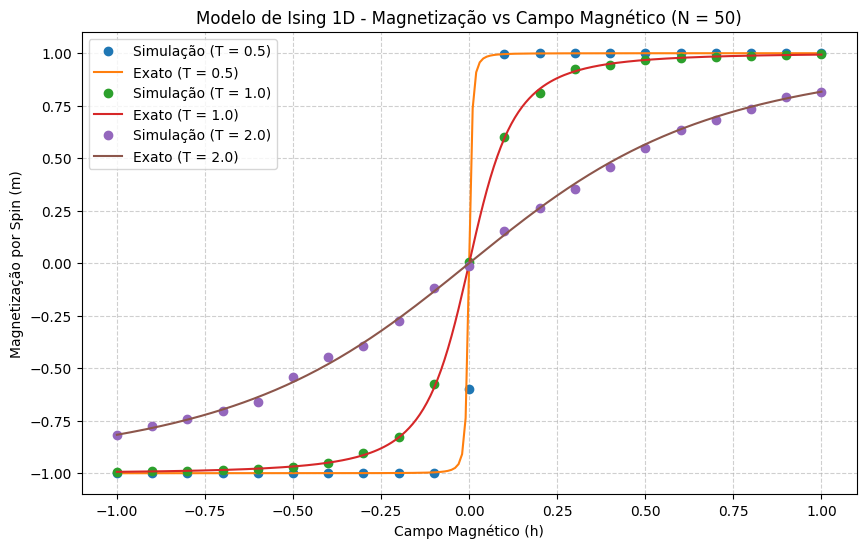

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit  #utilizado como indicado no VPL para acelerar a depuração.

# Parâmetros
N = 50  # Número de spins
T_lista = [0.5, 1.0, 2.0]  # Lista de valores da temperatura
J = 1.0  # Constante de interação entre spins
h_lista = np.arange(-1.0, 1.1, 0.1)  # Lista de valores do campo magnético para a simulação
h_exato = np.arange(-1.0, 1.01, 0.01)  # Lista de valores do campo magnético para o resultado exato
Passos = 1000  # Número de passos de Monte Carlo para medidas
Equilibra = 1000  # Número de passos de Monte Carlo para equilibração

pi1 = [] # vetor que deve guardar os valores de pi estimados pelo primeiro método
pi2 = [] # vetor que deve guardar os valores de pi estimados pelo segundo método

# Função que executa um passo de Monte Carlo
@jit(nopython=True)  # A função abaixo será compilada na primeira execução
def passo_MC(s, T, h):
    # Sorteamos N spins para propor um a um que sejam flipados
    #código aula 13
    for _ in range(N):
        j = np.random.randint(0, N)  # Sorteia um índice de spin de 0 a N-1

        # Condições de contorno periódicas usando o operador de resto (%)
        esquerda = s[(j - 1) % N]
        direita = s[(j + 1) % N]

        # Variação de energia (Delta E) caso o spin j inverta de sinal
        dE = 2 * s[j] * (J * (esquerda + direita) + h)

        # Critério de aceitação de Metropolis
        if dE <= 0 or np.random.random() < np.exp(-dE / T):
            s[j] = -s[j]  # Aceita o flip do spin

    return s

# Preparação dos gráficos
plt.figure(figsize=(10, 6))

# Laço mais externo percorre as temperaturas.
# Laço seguinte percorre os campos.
for it in range(len(T_lista)):
    T = T_lista[it]
    mag_medias = []  # Lista para armazenar a magnetização média para cada h nesta temperatura T

    for ih in range(len(h_lista)):
        h = h_lista[ih]

        # Configuração inicial aleatória
        s = 1 - 2 * np.random.randint(2, size=N)

        #passos de MC de equilibração
        for passo in range(Equilibra):
            s = passo_MC(s, T, h)

        #passos de MC para medidas

        mag_acumulada = 0.0
        for passo in range(Passos):
            s = passo_MC(s, T, h) #função aula 13 chamada
            # A magnetização por spin de uma configuração é a média dos spins: sum(s)/N
            mag_acumulada += np.mean(s)

        # Calcula a média temporal da magnetização para o campo h atual
        mag_final = mag_acumulada / Passos
        mag_medias.append(mag_final)

    #Ising 1D

    # Usando o método da Matriz de Transferência no limite termodinâmico
    numerador = np.sinh(h_exato / T)
    denominador = np.sqrt(np.sinh(h_exato / T)**2 + np.exp(-4 * J / T))
    mag_teorica = numerador / denominador

    #plot

    # Pontos representando a simulação de Monte Carlo
    plt.plot(h_lista, mag_medias, 'o', label=f'Simulação (T = {T})')
    # Linha contínua representando a solução exata esperada
    plt.plot(h_exato, mag_teorica, '-', label=f'Exato (T = {T})')

# Configurações estéticas do gráfico final
plt.title(f'Modelo de Ising 1D - Magnetização vs Campo Magnético (N = {N})')
plt.xlabel('Campo Magnético (h)')
plt.ylabel('Magnetização por Spin (m)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.savefig(f'magnetizacao_ising_1d_N{N}.png', dpi=300)
plt.show()
